## Step 1 — Environment Setup, Reproducibility & Dual-GPU Strategy

In [1]:
# === CELL 1: Setup — reproducibility, working dirs, dual-GPU strategy, dataset discovery ===

import os, random, warnings
import numpy as np
import tensorflow as tf

warnings.filterwarnings("ignore")

# --- Reproducibility ---
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Working dirs ---
WORKING_DIR = "/kaggle/working"
for sub in ["checkpoints", "logs", "gradcam", "results"]:
    os.makedirs(f"{WORKING_DIR}/{sub}", exist_ok=True)

# --- Multi-GPU strategy (both Kaggle T4s) ---
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs detected: {len(gpus)}")
for g in gpus:
    print(f"  -> {g}")

strategy = tf.distribute.MirroredStrategy()
print(f"Number of replicas in sync: {strategy.num_replicas_in_sync}")

print(f"\nTensorFlow version: {tf.__version__}")

# --- Dataset discovery (now expecting TWO datasets under /kaggle/input) ---
print("\nContents of /kaggle/input:\n")
for dirname, subdirs, filenames in os.walk("/kaggle/input"):
    depth = dirname.replace("/kaggle/input", "").count(os.sep)
    if depth <= 4:  # a bit deeper than before, since we now have 2 dataset trees
        indent = "  " * depth
        print(f"{indent}{dirname}  ({len(filenames)} files)" if filenames else f"{indent}{dirname}")

GPUs detected: 2
  -> PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  -> PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of replicas in sync: 2

TensorFlow version: 2.20.0

Contents of /kaggle/input:

/kaggle/input
  /kaggle/input/datasets
    /kaggle/input/datasets/sachchitkunichetty
      /kaggle/input/datasets/sachchitkunichetty/rvf10k  (2 files)
        /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k


I0000 00:00:1784362746.410955      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784362746.414087      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


    /kaggle/input/datasets/troykueh
      /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3  (1 files)
        /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Real faces  (10000 files)
        /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Fake faces  (10000 files)


## Step 2 — Dataset Discovery, Labeling & Per-Dataset Stratified Split

In [2]:
# === CELL 2: Load both datasets, tag by source, per-dataset stratified split, unified manifest ===

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

LABEL_MAP = {"fake": 0, "real": 1}
VALID_EXT = (".jpg", ".jpeg", ".png")

def list_images_with_labels(class_dirs_dict):
    """{'fake': [Path,...], 'real': [Path,...]} -> parallel (paths, labels) lists."""
    paths, labels = [], []
    for class_name, dir_list in class_dirs_dict.items():
        label = LABEL_MAP[class_name]
        for d in dir_list:
            for f in sorted(os.listdir(d)):
                if f.lower().endswith(VALID_EXT):
                    paths.append(str(d / f))
                    labels.append(label)
    return paths, labels

def stratified_split_fractions(paths, labels, train_frac=0.7, val_frac=0.2, test_frac=0.1, seed=SEED):
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9
    p_train, p_temp, l_train, l_temp = train_test_split(
        paths, labels, train_size=train_frac, stratify=labels, random_state=seed
    )
    rel_val = val_frac / (val_frac + test_frac)
    p_val, p_test, l_val, l_test = train_test_split(
        p_temp, l_temp, train_size=rel_val, stratify=l_temp, random_state=seed
    )
    return (p_train, l_train), (p_val, l_val), (p_test, l_test)

# --- Dataset 1: RVF-10K ---
RVF10K_ROOT = Path("/kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k")
RVF10K_DIRS = {
    "fake": [RVF10K_ROOT / "train" / "fake", RVF10K_ROOT / "valid" / "fake"],
    "real": [RVF10K_ROOT / "train" / "real", RVF10K_ROOT / "valid" / "real"],
}

# --- Dataset 2: StyleGAN3 real-vs-fake ---
SGAN3_ROOT = Path("/kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3")
SGAN3_DIRS = {
    "fake": [SGAN3_ROOT / "Fake faces"],
    "real": [SGAN3_ROOT / "Real faces"],
}

DATASETS = {
    "rvf10k": RVF10K_DIRS,
    "sgan3": SGAN3_DIRS,
}

manifest_parts = []
print("Per-dataset counts:\n")
for ds_name, ds_dirs in DATASETS.items():
    paths, labels = list_images_with_labels(ds_dirs)
    n_fake, n_real = labels.count(0), labels.count(1)
    print(f"[{ds_name}] total={len(paths)}  fake={n_fake}  real={n_real}")

    (p_tr, l_tr), (p_va, l_va), (p_te, l_te) = stratified_split_fractions(paths, labels)
    print(f"  -> train={len(p_tr)}  val={len(p_va)}  test={len(p_te)}\n")

    for p_split, l_split, split_name in [(p_tr, l_tr, "train"), (p_va, l_va, "val"), (p_te, l_te, "test")]:
        manifest_parts.append(pd.DataFrame({
            "path": p_split, "label": l_split, "dataset": ds_name, "split": split_name
        }))

manifest_df = pd.concat(manifest_parts, ignore_index=True)

# --- Leakage checks: within each dataset, across its own splits ---
for ds_name in DATASETS:
    sub = manifest_df[manifest_df["dataset"] == ds_name]
    sets = {s: set(sub[sub["split"] == s]["path"]) for s in ["train", "val", "test"]}
    assert not (sets["train"] & sets["val"]),  f"{ds_name}: leakage train/val!"
    assert not (sets["train"] & sets["test"]), f"{ds_name}: leakage train/test!"
    assert not (sets["val"]   & sets["test"]), f"{ds_name}: leakage val/test!"
assert manifest_df["path"].is_unique, "Duplicate path across datasets — check for overlap!"
print("No leakage within or across datasets — confirmed.\n")

print("Combined manifest summary:")
print(manifest_df.groupby(["dataset", "split", "label"]).size().unstack(fill_value=0))

manifest_df.to_csv(f"{WORKING_DIR}/results/manifest.csv", index=False)
print(f"\nManifest saved: {WORKING_DIR}/results/manifest.csv  ({len(manifest_df)} rows)")
manifest_df.head()

Per-dataset counts:

[rvf10k] total=10000  fake=5000  real=5000
  -> train=7000  val=2000  test=1000

[sgan3] total=20000  fake=10000  real=10000
  -> train=14000  val=4000  test=2000

No leakage within or across datasets — confirmed.

Combined manifest summary:
label             0     1
dataset split            
rvf10k  test    500   500
        train  3500  3500
        val    1000  1000
sgan3   test   1000  1000
        train  7000  7000
        val    2000  2000

Manifest saved: /kaggle/working/results/manifest.csv  (30000 rows)


,path,label,dataset,split
0,/kaggle/input/datasets/sachchitkunichetty/rvf1...,1,rvf10k,train
1,/kaggle/input/datasets/sachchitkunichetty/rvf1...,0,rvf10k,train
2,/kaggle/input/datasets/sachchitkunichetty/rvf1...,0,rvf10k,train
3,/kaggle/input/datasets/sachchitkunichetty/rvf1...,0,rvf10k,train
4,/kaggle/input/datasets/sachchitkunichetty/rvf1...,1,rvf10k,train


## Step 2.5 — Sample Image Gallery for the Paper

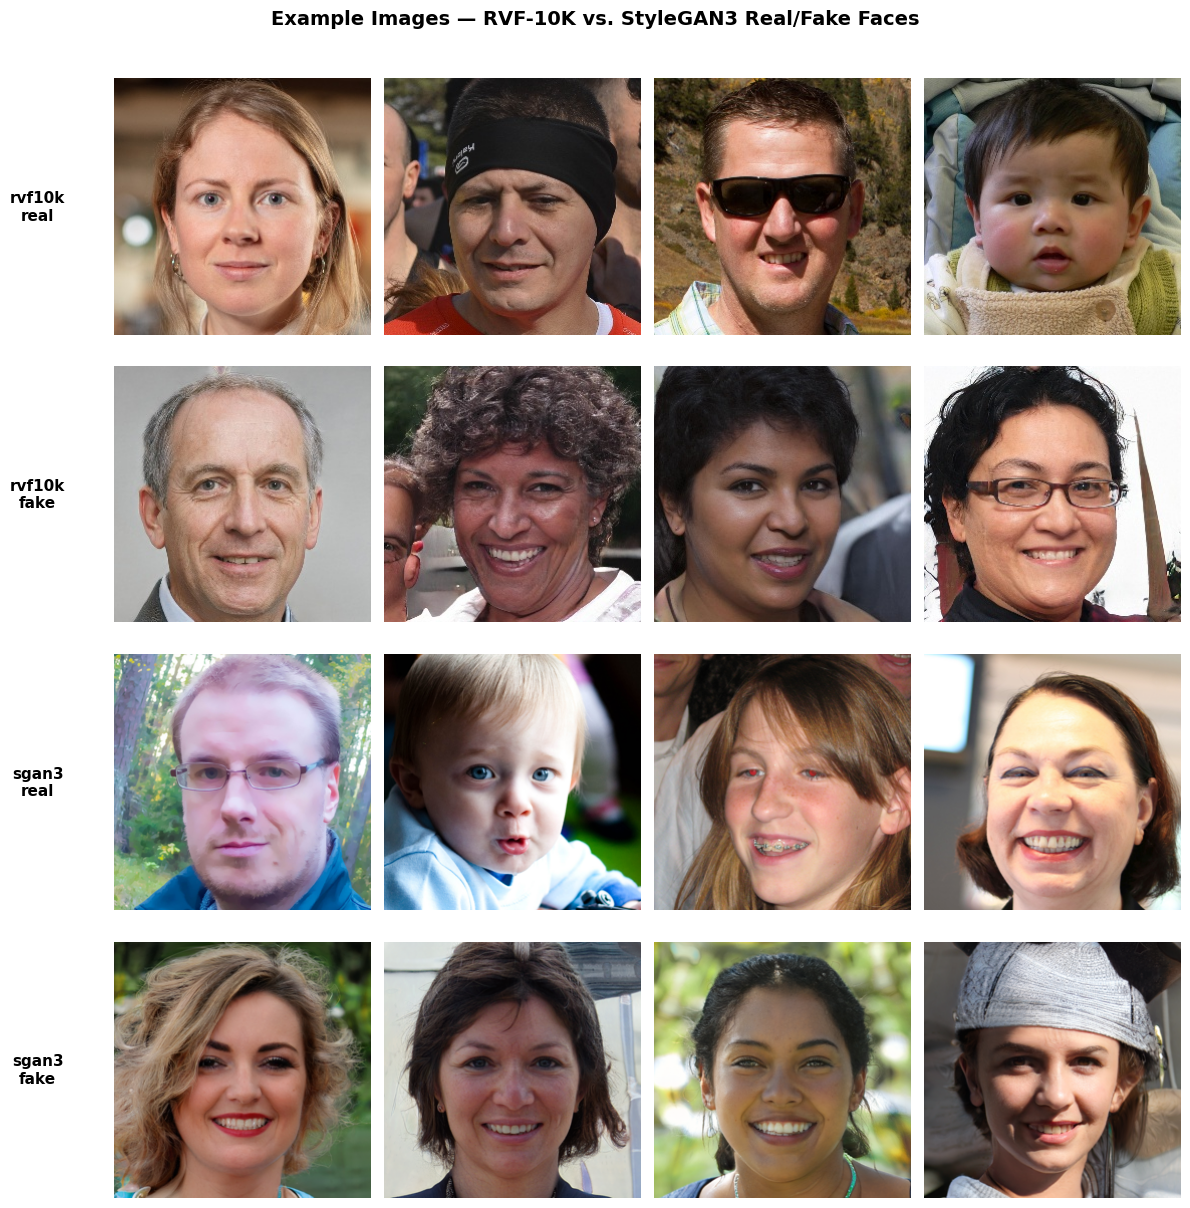

Saved 16 individual sample images to /kaggle/working/results/samples/
Saved composite grid: /kaggle/working/results/samples/sample_grid.png
Saved composite grid (vector): /kaggle/working/results/samples/sample_grid.pdf  (use this one in the paper)
Saved samples manifest: /kaggle/working/results/samples/samples_manifest.csv


In [3]:
# === CELL 2.5: Save example images from each dataset for the paper ===

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import shutil

N_SAMPLES_PER_GROUP = 4   # images per (dataset, label) combination
SAMPLES_DIR = f"{WORKING_DIR}/results/samples"
os.makedirs(SAMPLES_DIR, exist_ok=True)

LABEL_NAMES = {0: "fake", 1: "real"}
groups = [(ds_name, label) for ds_name in DATASETS for label in [1, 0]]  # real, then fake — reads naturally

fig, axes = plt.subplots(len(groups), N_SAMPLES_PER_GROUP,
                          figsize=(3 * N_SAMPLES_PER_GROUP, 3 * len(groups)))

sample_records = []

for row, (ds_name, label) in enumerate(groups):
    subset = manifest_df[
        (manifest_df["dataset"] == ds_name) &
        (manifest_df["label"] == label) &
        (manifest_df["split"] == "train")   # train split only — test/val stay untouched
    ]
    sampled = subset.sample(n=N_SAMPLES_PER_GROUP, random_state=SEED)

    for col, (_, row_data) in enumerate(sampled.iterrows()):
        src_path = row_data["path"]
        ax = axes[row, col]
        img = mpimg.imread(src_path)
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.set_ylabel(f"{ds_name}\n{LABEL_NAMES[label]}", fontsize=11,
                           fontweight="bold", rotation=0, labelpad=55, va="center")

        # Save a standalone copy too, for direct use in the paper
        dst_name = f"{ds_name}_{LABEL_NAMES[label]}_{col}{Path(src_path).suffix}"
        dst_path = f"{SAMPLES_DIR}/{dst_name}"
        shutil.copy(src_path, dst_path)
        sample_records.append({"dataset": ds_name, "label": label,
                                "src_path": src_path, "saved_as": dst_path})

fig.suptitle("Example Images — RVF-10K vs. StyleGAN3 Real/Fake Faces",
             fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()

grid_png = f"{SAMPLES_DIR}/sample_grid.png"
grid_pdf = f"{SAMPLES_DIR}/sample_grid.pdf"
fig.savefig(grid_png, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(grid_pdf, bbox_inches="tight", facecolor="white")
plt.show()

samples_manifest = pd.DataFrame(sample_records)
samples_manifest.to_csv(f"{SAMPLES_DIR}/samples_manifest.csv", index=False)

print(f"Saved {len(sample_records)} individual sample images to {SAMPLES_DIR}/")
print(f"Saved composite grid: {grid_png}")
print(f"Saved composite grid (vector): {grid_pdf}  (use this one in the paper)")
print(f"Saved samples manifest: {SAMPLES_DIR}/samples_manifest.csv")

## Step 3 — tf.data Pipeline with Balanced Dataset Interleaving

In [4]:
# === CELL 3: tf.data pipeline — robust decoding + balanced train interleaving ===

IMG_SIZE = (256, 256)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

from tensorflow.keras.applications.vgg19 import preprocess_input

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)  # format-agnostic (jpg/png/bmp)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)  # VGG19-specific preprocessing (BGR + mean subtraction)
    return img, label

def get_split(ds_name, split):
    """Manifest is the single source of truth — pull paths/labels straight from it."""
    sub = manifest_df[(manifest_df["dataset"] == ds_name) & (manifest_df["split"] == split)]
    return sub["path"].tolist(), sub["label"].tolist()

def unbatched_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    return ds

# --- Per-dataset train streams, balanced 50/50 regardless of size ---
p_rvf_tr, l_rvf_tr = get_split("rvf10k", "train")
p_sgan3_tr, l_sgan3_tr = get_split("sgan3", "train")

rvf_train_stream = unbatched_dataset(p_rvf_tr, l_rvf_tr, shuffle=True).repeat()
sgan3_train_stream = unbatched_dataset(p_sgan3_tr, l_sgan3_tr, shuffle=True).repeat()

train_ds = tf.data.Dataset.sample_from_datasets(
    [rvf_train_stream, sgan3_train_stream], weights=[0.5, 0.5], seed=SEED
)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

n_train_total = len(p_rvf_tr) + len(p_sgan3_tr)
STEPS_PER_EPOCH = n_train_total // BATCH_SIZE
print(f"Train pool: rvf10k={len(p_rvf_tr)}  sgan3={len(p_sgan3_tr)}  combined={n_train_total}")
print(f"STEPS_PER_EPOCH = {STEPS_PER_EPOCH}  (one 'epoch' = one pass over the combined pool)")

# --- Val / test: pooled normally, no reweighting, no repeat ---
def build_pooled_dataset(split):
    p_rvf, l_rvf = get_split("rvf10k", split)
    p_sgan3, l_sgan3 = get_split("sgan3", split)
    paths = p_rvf + p_sgan3
    labels = l_rvf + l_sgan3
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds, len(paths)

val_ds, n_val = build_pooled_dataset("val")
test_ds, n_test = build_pooled_dataset("test")
print(f"\nval_ds  : {n_val} images, {len(val_ds)} batches")
print(f"test_ds : {n_test} images, {len(test_ds)} batches")

# --- Sanity check: pull one real batch, confirm shapes/dtypes ---
for imgs, lbls in train_ds.take(1):
    print(f"\nBatch image shape: {imgs.shape}, dtype: {imgs.dtype}")
    print(f"Batch label shape: {lbls.shape}, dtype: {lbls.dtype}")
    print(f"Sample labels: {lbls.numpy()[:10]}")

# --- Diagnostic: empirically verify the 50/50 sampling ratio (cheap — no image decode) ---
rvf_id_stream = tf.data.Dataset.from_tensor_slices(tf.zeros(len(p_rvf_tr), dtype=tf.int32)).repeat()
sgan3_id_stream = tf.data.Dataset.from_tensor_slices(tf.ones(len(p_sgan3_tr), dtype=tf.int32)).repeat()
mixed_id_ds = tf.data.Dataset.sample_from_datasets([rvf_id_stream, sgan3_id_stream], weights=[0.5, 0.5], seed=SEED)

N_CHECK = 5000
sample_ids = np.array(list(mixed_id_ds.take(N_CHECK).as_numpy_iterator()))
rvf_pct = (sample_ids == 0).mean() * 100
sgan3_pct = (sample_ids == 1).mean() * 100
print(f"\nSampling ratio check (n={N_CHECK}): rvf10k={rvf_pct:.1f}%  sgan3={sgan3_pct:.1f}%  (target: 50/50)")

Train pool: rvf10k=7000  sgan3=14000  combined=21000
STEPS_PER_EPOCH = 328  (one 'epoch' = one pass over the combined pool)

val_ds  : 6000 images, 94 batches
test_ds : 3000 images, 47 batches

Batch image shape: (64, 256, 256, 3), dtype: <dtype: 'float32'>
Batch label shape: (64,), dtype: <dtype: 'int32'>
Sample labels: [0 1 1 1 1 0 0 1 1 0]

Sampling ratio check (n=5000): rvf10k=48.5%  sgan3=51.5%  (target: 50/50)


## Step 4 — Model Architecture (VGG19 Backbone + Custom Head)

VGG19 pretrained on ImageNet, with blocks 1–3 frozen (generic low-level features)
and blocks 4–5 fine-tuned (higher-level, face-relevant features), followed by a
custom head: Conv2D(512) → BatchNorm → MaxPool → Dropout(0.4) → GlobalAveragePooling
→ Dense(512, L2-regularized) → BatchNorm → ReLU → Dropout(0.4) → sigmoid output.
Architecture is unchanged from the single-dataset version — the two-dataset setup
only changes what data reaches the model (Steps 2–3), not the model itself. Built
inside `strategy.scope()` for dual-GPU training.

In [5]:
# === CELL 4: Model architecture — VGG19 backbone (block4/5 trainable) + custom head ===

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import VGG19

input_shape = (*IMG_SIZE, 3)  # (256, 256, 3)

with strategy.scope():
    inputs = layers.Input(shape=input_shape, name="input_layer")

    vgg19_base = VGG19(include_top=False, weights="imagenet", input_shape=input_shape)

    # Freeze everything first, then selectively unfreeze deeper blocks.
    # Early layers capture generic edges/textures that transfer well as-is;
    # block4/5 capture higher-level features worth adapting to faces.
    for layer in vgg19_base.layers:
        layer.trainable = False
    for layer in vgg19_base.layers:
        if layer.name.startswith("block4") or layer.name.startswith("block5"):
            layer.trainable = True

    x = vgg19_base(inputs)

    x = layers.Conv2D(512, (3, 3), padding="same", activation="relu", name="extra_conv")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.4, name="dropout_conv")(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(512, kernel_regularizer=regularizers.l2(0.0001), name="dense_512")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4, name="dropout_dense")(x)

    outputs = layers.Dense(1, activation="sigmoid", name="output")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="DeepFake_Detector")

trainable_count = sum([tf.size(w).numpy() for w in model.trainable_weights])
total_count = sum([tf.size(w).numpy() for w in model.weights])
print(f"Trainable parameters: {trainable_count:,}")
print(f"Total parameters:     {total_count:,}")

model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 20,323,841
Total parameters:     22,651,457


Model: "DeepFake_Detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ extra_conv (Conv2D)             │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,651,457 (86.41 MB)

 Trainable params: 20,323,841 (77.53 MB)

 Non-trainable params: 2,327,616 (8.88 MB)

## Step 5 — Compile Model (AdamW) + Callbacks

Compiles with AdamW (weight decay 1e-4, gradient clipnorm 1.0, EMA weights,
momentum 0.99) and binary cross-entropy with label smoothing (0.1) to curb
overconfidence. Configures EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
and CSVLogger. Unchanged from the single-dataset version — these are model-level
choices, independent of how many datasets feed the training loop.

In [6]:
# === CELL 5: Compile model + callbacks ===

initial_lr = 1e-5  # lowered from 2e-5 — less aggressive steps on an already high-capacity trainable backbone

with strategy.scope():
    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=initial_lr,
        weight_decay=1e-4,
        clipnorm=1.0,          # gradient clipping — caps the size of any single update
        use_ema=True,          # maintain an EMA of weights, used for validation/inference
        ema_momentum=0.99,
    )

    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.1),  # softens targets, curbs overconfidence
        metrics=["accuracy"],
    )

print("Model compiled with AdamW (EMA + gradient clipping + label smoothing)")
print(f"Initial learning rate: {initial_lr}")
print(f"Weight decay: {optimizer.weight_decay}")
print(f"Gradient clipnorm: 1.0")
print(f"EMA momentum: 0.99")

# --- Callbacks ---
checkpoint_path = f"{WORKING_DIR}/checkpoints/best_model.keras"
csv_log_path = f"{WORKING_DIR}/logs/training_log.csv"

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,          # tightened from 4 — backs off LR faster once instability starts
    min_lr=1e-7,
    verbose=1,
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

csv_logger = tf.keras.callbacks.CSVLogger(csv_log_path, append=False)

callbacks_list = [early_stop, reduce_lr, checkpoint_cb, csv_logger]

print("\nCallbacks configured:")
print(f"  EarlyStopping     patience=8, monitor=val_loss, restore_best_weights=True")
print(f"  ReduceLROnPlateau factor=0.5, patience=2, min_lr=1e-7")
print(f"  ModelCheckpoint   -> {checkpoint_path}")
print(f"  CSVLogger         -> {csv_log_path}")

Model compiled with AdamW (EMA + gradient clipping + label smoothing)
Initial learning rate: 1e-05
Weight decay: 0.0001
Gradient clipnorm: 1.0
EMA momentum: 0.99

Callbacks configured:
  EarlyStopping     patience=8, monitor=val_loss, restore_best_weights=True
  ReduceLROnPlateau factor=0.5, patience=2, min_lr=1e-7
  ModelCheckpoint   -> /kaggle/working/checkpoints/best_model.keras
  CSVLogger         -> /kaggle/working/logs/training_log.csv


## Step 6 — Train the Model

Trains for up to 25 epochs (EarlyStopping on val_loss, patience=8, will likely
stop earlier), using the balanced 50/50 dataset-interleaved training stream and
the pooled validation stream. `steps_per_epoch` is required here since the
training stream is repeated indefinitely to support balanced sampling — without
it Keras cannot detect epoch boundaries. After training, EMA-averaged weights are
written into the model (required for `use_ema=True` to actually take effect on
saved/evaluated weights).

In [7]:
# === CELL 6: Train the model ===

EPOCHS = 35  # ceiling — EarlyStopping (patience=8 on val_loss) will likely cut this shorter

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,   # required: train_ds is repeat()-ed for balanced sampling
    callbacks=callbacks_list,
    verbose=1,
)

# Write the EMA-averaged weights into the model — without this, use_ema=True
# in the optimizer has no effect on the weights you actually save/evaluate.
model.optimizer.finalize_variable_values(model.trainable_variables)

print("\nTraining complete.")
print(f"Stopped at epoch: {len(history.history['loss'])}")
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"Best epoch (lowest val_loss): {best_epoch}")
print(f"Best val_loss: {min(history.history['val_loss']):.4f}")
print(f"Best val_accuracy: {history.history['val_accuracy'][best_epoch-1]:.4f}")

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

E0000 00:00:1784362832.121178      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/DeepFake_Detector_1/dropout_conv_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.6491 - loss: 0.7509INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from None to 0.50096, saving model to /kaggle/working/checkpoints/best_model.keras

Epoch 1: finished saving model to /kaggle/working/checkpoints/best_model.keras
328/328 ━━━━━━━━━━━━━━━━━━━━ 205s 570ms/step - accuracy: 0.7213 - loss: 0.6624 - val_accuracy: 0.8317 - val_loss: 0.5010 - learning_rate: 1.0000e-05
Epoch 2/35
328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step - accuracy: 0.8349 - loss: 0.5153
Epoch 2: val_loss improved from 0.50096 to 0.44462, saving model to /kaggle/working/checkpoints/best_model.keras

Epoch 2: finished saving model to /kaggle/working/checkpoints/best_model.keras
328/328 ━━━━━━━━━━━━━━━

## Step 6.5 — Save Final Model & Plot Training Curves

Saves the final (best-weights-restored) model in Keras format, backs up the
training history as JSON, and plots loss/accuracy curves with the best
epoch marked, saving publication-quality PNG + PDF versions.

Final model saved: /kaggle/working/checkpoints/final_model.keras
Best-checkpoint model (from ModelCheckpoint): /kaggle/working/checkpoints/best_model.keras
History saved: /kaggle/working/results/history.json


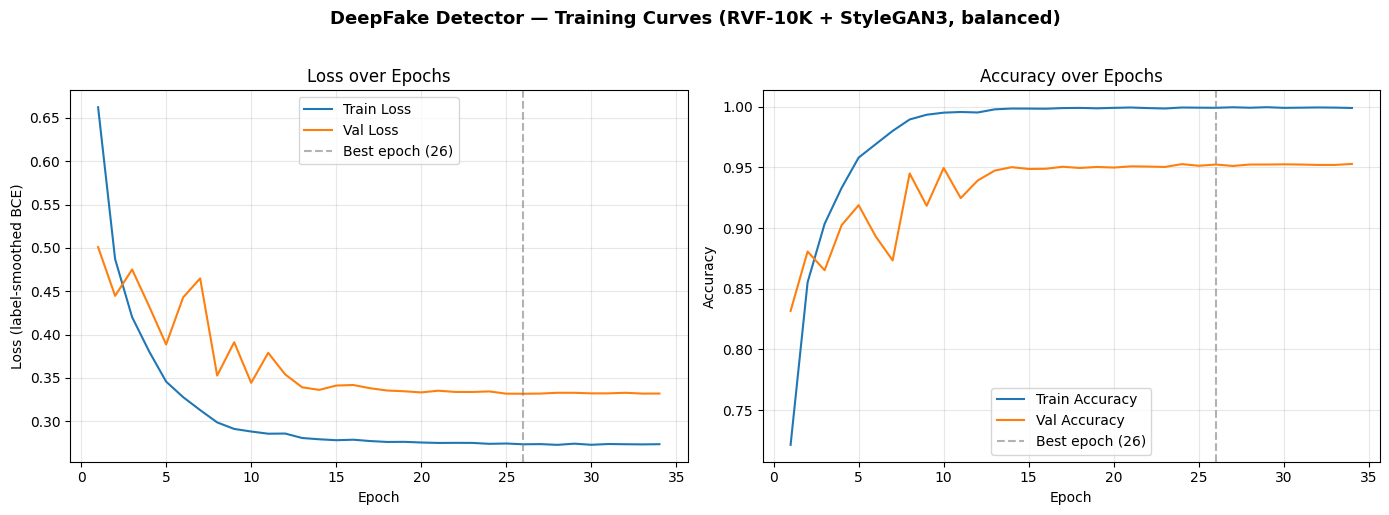


Saved: /kaggle/working/results/training_curves.png
Saved (vector, for paper): /kaggle/working/results/training_curves.pdf
Best epoch: 26  |  val_loss=0.3316  |  val_accuracy=0.9523


In [8]:
# === CELL 6.5: Save model + plot training curves ===
import json
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = f"{WORKING_DIR}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# --- 1. Explicit final save (redundant safety net alongside ModelCheckpoint) ---
# model already holds best weights in memory (restore_best_weights=True fired),
# and EMA weights were finalized in Cell 6 — this just makes sure a copy
# with the EXACT final in-memory state exists on disk too.
final_model_path = f"{WORKING_DIR}/checkpoints/final_model.keras"
model.save(final_model_path)
print(f"Final model saved: {final_model_path}")
print(f"Best-checkpoint model (from ModelCheckpoint): {checkpoint_path}")

# --- 2. Save history dict as JSON (so you can replot without retraining) ---
history_path = f"{RESULTS_DIR}/history.json"
with open(history_path, "w") as f:
    json.dump(history.history, f)
print(f"History saved: {history_path}")

# --- 3. Plot loss + accuracy, best epoch marked ---
h = history.history
best_epoch = int(np.argmin(h["val_loss"]))  # 0-indexed here, matches array position
epochs_range = range(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, h["loss"], label="Train Loss")
axes[0].plot(epochs_range, h["val_loss"], label="Val Loss")
axes[0].axvline(best_epoch + 1, color="gray", linestyle="--", alpha=0.6,
                 label=f"Best epoch ({best_epoch + 1})")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss (label-smoothed BCE)")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, h["accuracy"], label="Train Accuracy")
axes[1].plot(epochs_range, h["val_accuracy"], label="Val Accuracy")
axes[1].axvline(best_epoch + 1, color="gray", linestyle="--", alpha=0.6,
                 label=f"Best epoch ({best_epoch + 1})")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)

fig.suptitle("DeepFake Detector — Training Curves (RVF-10K + StyleGAN3, balanced)",
             fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()

curve_png = f"{RESULTS_DIR}/training_curves.png"
curve_pdf = f"{RESULTS_DIR}/training_curves.pdf"
fig.savefig(curve_png, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(curve_pdf, bbox_inches="tight", facecolor="white")  # vector, use this in the paper
plt.show()

print(f"\nSaved: {curve_png}")
print(f"Saved (vector, for paper): {curve_pdf}")
print(f"Best epoch: {best_epoch + 1}  |  val_loss={h['val_loss'][best_epoch]:.4f}  "
      f"|  val_accuracy={h['val_accuracy'][best_epoch]:.4f}")